In [25]:
import numpy as np 
import matplotlib.pyplot as plt
from brokenaxes import brokenaxes
from matplotlib.patches import Rectangle
from matplotlib.ticker import MultipleLocator, AutoMinorLocator
from scipy.interpolate import make_interp_spline
from astropy.io import ascii
from astropy.time import Time

In [26]:
ms_style_dict = {'text.usetex': True, 'font.family': 'serif',
                 'font.serif': ['Computer Modern Roman'], 'axes.linewidth': 1.2,
                 'xtick.major.width': 1.2, 'xtick.major.size': 4,
                 'ytick.major.width': 1.2, 'ytick.major.size': 4,
                 'xtick.minor.width': 1.2, 'xtick.minor.size': 2,
                 'ytick.minor.width': 1.2, 'ytick.minor.size': 2,
                 'xtick.direction': 'in', 'ytick.direction': 'in',
                 'text.latex.preamble': r'\usepackage[T1]{fontenc}'
                 r'\usepackage{amsmath}' r'\usepackage{siunitx}'
                 r'\sisetup{detect-all=True}' r'\usepackage{fixltx2e}'}

In [27]:
theta_50_vs_height_ensemble_dict = np.load("../../data/pid_1_123_aux/MHSXtra_results_new/theta_50_vs_height/theta_50_vs_height_all_ensemble.npz")
theta_50_vs_height_null_ensemble_dict = np.load("../../data/pid_1_123_aux/MHSXtra_results_new/theta_50_vs_height//theta_50_vs_height_null_ensemble.npz")

In [28]:
list(theta_50_vs_height_ensemble_dict.keys())

['theta_50_vs_height_all_ensemble',
 'mhs_new_alpha_list',
 'theta_50_height_mhs',
 'theta_50_vs_height_nlfff_ensemble',
 'theta_50_height_nlfff']

In [29]:
list(theta_50_vs_height_null_ensemble_dict.keys())

['theta_50_vs_height_0014_null_ensemble', 'theta_50_height_mhs']

In [30]:
legends = [rf"${alpha_:.3f}$" for alpha_ in theta_50_vs_height_ensemble_dict["mhs_new_alpha_list"]] + ["NLFFF", "null"]

In [31]:
legends

['$-0.010$',
 '$0.000$',
 '$0.002$',
 '$0.004$',
 '$0.006$',
 '$0.010$',
 '$0.012$',
 '$0.014$',
 '$0.016$',
 '$0.018$',
 '$0.020$',
 'NLFFF',
 'null']

In [32]:
theta_50_vs_height_ensemble_dict["theta_50_vs_height_all_ensemble"].shape

(11, 100, 12)

In [33]:
theta_50_vs_height_ensemble_dict["theta_50_height_mhs"][20]

np.float64(1.0)

In [34]:
theta_50_vs_height_ensemble_dict["theta_50_height_nlfff"][4]

np.float64(0.9485060879787359)

In [35]:
np.unravel_index(
    np.nanargmin(theta_50_vs_height_ensemble_dict["theta_50_vs_height_all_ensemble"]),
    theta_50_vs_height_ensemble_dict["theta_50_vs_height_all_ensemble"].shape
)

(np.int64(8), np.int64(22), np.int64(9))

In [36]:
theta_50_vs_height_ensemble_dict["mhs_new_alpha_list"][7]

np.float32(0.014)

In [37]:
theta_50_vs_height_ensemble_dict["theta_50_vs_height_all_ensemble"].flat[
    np.nanargmin(theta_50_vs_height_ensemble_dict["theta_50_vs_height_all_ensemble"])]

np.float64(10.335877997179132)

In [38]:
f_theta_50_nlfff = make_interp_spline(
    theta_50_vs_height_ensemble_dict["theta_50_height_nlfff"],
    theta_50_vs_height_ensemble_dict["theta_50_vs_height_nlfff_ensemble"],
    axis=0, k=3
)
theta_50_near_1_Mm_ensemble = np.vstack([
    np.nanmean(theta_50_vs_height_ensemble_dict["theta_50_vs_height_all_ensemble"][:,19:22,:], axis=1),
    f_theta_50_nlfff(1.0),
    np.nanmean(theta_50_vs_height_null_ensemble_dict["theta_50_vs_height_0014_null_ensemble"][19:22,:],axis=0)
]
)

In [39]:
theta_50_vs_height_ensemble_dict["theta_50_height_nlfff"].shape

(20,)

In [40]:
theta_50_vs_height_null_ensemble_dict["theta_50_vs_height_0014_null_ensemble"].shape

(100, 12)

In [41]:
ensemble_index = 7
curves = [curve_ for curve_ in theta_50_vs_height_ensemble_dict["theta_50_vs_height_all_ensemble"][:,:,ensemble_index]] + \
         [theta_50_vs_height_ensemble_dict["theta_50_vs_height_nlfff_ensemble"][:,ensemble_index],
          theta_50_vs_height_null_ensemble_dict["theta_50_vs_height_0014_null_ensemble"][:,ensemble_index]]

In [42]:
heights = [theta_50_vs_height_ensemble_dict["theta_50_height_mhs"]]*11 + \
        [theta_50_vs_height_ensemble_dict["theta_50_height_nlfff"]] + \
        [theta_50_vs_height_ensemble_dict["theta_50_height_mhs"]]

In [43]:
Hbeta_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/Hbeta_BJOLO_date_avg.txt")["DATE-AVG"])

/scratch/tmp.18571374.zhuyin/ipykernel_85632/62429017.py:68: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.savefig("../../figs/ms_figure/app_extrapolation_validate.pdf", bbox_inches="tight")
/scratch/tmp.18571374.zhuyin/ipykernel_85632/62429017.py:69: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.savefig("../../figs/ms_figure_png/app_extrapolation_validate.png", bbox_inches="tight")
/cluster/software/stacks/2024-05/python-cuda/3.11.6/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


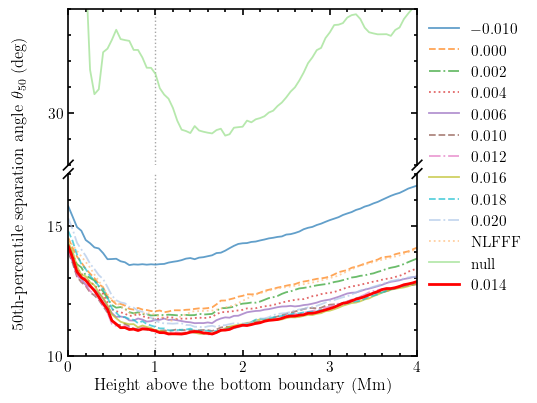

In [44]:
line_styles = ["-", "--", "-.", ":"]
cmap = plt.get_cmap("tab20")
colors = cmap.colors[::2] + cmap.colors[1::2]
highlight_index = 7

plt.close("all")

with plt.rc_context(ms_style_dict):
    fig = plt.figure(figsize=(4.5, 4.5), layout="constrained")

    bax = brokenaxes(
        ylims=((10., 17), (28, 34)),
        hspace=0.05,
        despine=False,
    )

    bax.set_xlim(0,4)

    for ii, (curve_, height_, legend_) in enumerate(zip(curves, heights, legends)):
        if ii == highlight_index:
            continue

        bax.plot(
            height_,
            curve_,
            color=colors[ii],
            label=legend_,
            linestyle=line_styles[ii % len(line_styles)],
            linewidth=1.3,
            alpha=0.7
        )
    
    bax.plot(
        heights[highlight_index],
        curves[highlight_index],
        color="red",
        label=legends[highlight_index],
        # linestyle=line_styles[highlight_index % len(line_styles)],
        linewidth=2,
        alpha=1,
    )



    for ax_ in bax.axs:
        ax_.yaxis.set_tick_params(right=True, labelsize=11)
    bax.axs[0].xaxis.set_tick_params(top=True)
    bax.axs[1].xaxis.set_tick_params(labelsize=11)

    
    bax.legend(ncols=1, frameon=False, bbox_to_anchor=(1.04,0,0.3,1), fontsize=11)
    
    # bax.tick_params(axis='both', which='major', top=True, right=True)
    bax.set_xlabel("Height above the bottom boundary (Mm)", fontsize=12)
    bax.set_ylabel(r"50th-percentile separation angle $\theta_{50}$ (deg)", fontsize=12)
    bax.axvline(1.0, color="gray", linestyle=":", linewidth=1., alpha=0.7, zorder=-1)

    for ax_ in bax.axs:
        ax_.yaxis.set_major_locator(MultipleLocator(5))
        ax_.yaxis.set_minor_locator(MultipleLocator(1))
        ax_.xaxis.set_major_locator(MultipleLocator(1))
        ax_.xaxis.set_minor_locator(MultipleLocator(0.2))
    
    bax.axs[0].tick_params(top=True, right=True, bottom=False,which="both")
    bax.axs[1].tick_params(top=False, right=True, which="both")


    fig.savefig("../../figs/ms_figure/app_extrapolation_validate.pdf", bbox_inches="tight")
    fig.savefig("../../figs/ms_figure_png/app_extrapolation_validate.png", bbox_inches="tight")
    plt.show()

    

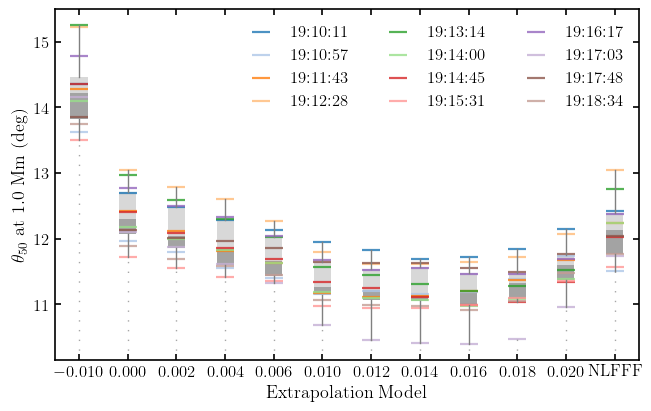

In [45]:
plt.close("all")

select_indices = np.arange(72, 128, 5)
ensemble_legends = [Hbeta_date_obs[select_index_].strftime("%H:%M:%S") for select_index_ in select_indices]

with plt.rc_context(ms_style_dict):
    fig, ax = plt.subplots(figsize=(8*0.8,5*0.8), layout="constrained")

    xpos = np.arange(12)

    box_width = 0.35
    bp = ax.boxplot(
        theta_50_near_1_Mm_ensemble[:12,:].T,
        positions=xpos,
        widths=box_width,
        patch_artist=True,
        showfliers=False,
        boxprops=dict(facecolor="none", edgecolor="none"),
        medianprops=dict(color="none", linewidth=2),
        whiskerprops=dict(color="0.5"),
        capprops=dict(color="0.5"),
        showcaps=False,
        tick_labels=legends[:12]
    )

    ax.relim()
    ax.autoscale_view()
    ax.set_autoscale_on(False)
    
    for ii, y in enumerate(theta_50_near_1_Mm_ensemble[:12,:], start=0):
        q1, med, q3 = np.percentile(y, [25, 50, 75])
        min_whisker = np.nanmin(y)

        # lower half: Q1 to median
        ax.add_patch(Rectangle(
            (ii - box_width/2, q1),   # (x_left, y_bottom)
            box_width,               # box width
            med - q1,            # height
            facecolor=[0.6, 0.6, 0.6, 0.9],
            edgecolor='none',
            zorder=-1
        ))

        # upper half: median to Q3
        ax.add_patch(Rectangle(
            (ii - box_width/2, med),
            box_width,
            q3 - med,
            facecolor=[0.7, 0.7, 0.7, 0.5],
            edgecolor='none',
            zorder=-1
        ))

        ax.vlines(ii, ax.get_ylim()[0], min_whisker, color="gray", linewidth=1, alpha=0.7,
            ls=(0,(1,6)))

    for ii in range(12):
        ln = ax.scatter(
                np.arange(12),
                theta_50_near_1_Mm_ensemble[:12,ii],
                # edgecolors=cmap.colors[ii],
                facecolors=list(cmap.colors[ii]) + [0.7],
                marker="_",
                # marker="o",
                alpha=0.8,
                linewidths=1.6,
                s=150,
                label=ensemble_legends[ii],
        )
    ax.set_ylabel(r"$\theta_{50}$ at 1.0 Mm (deg)", fontsize=13)
    ax.set_xlabel("Extrapolation Model", fontsize=13)
    ax.tick_params(labelsize=12)

    ax.legend(ncols=3, frameon=False, fontsize=12, loc="upper right")
    ax.tick_params(axis='both', which='major', top=True, right=True)

    
    
    # ax.set_xticks(np.arange(12))
    # ax.set_xticklabels(legends[:12])
    fig.savefig("../../figs/ms_figure/app_extrapolation_validate_boxplot.pdf", bbox_inches="tight")

    plt.show()

In [46]:
all_median = np.nanmedian(theta_50_near_1_Mm_ensemble, axis=1)

for legend_, median_ in zip(legends, all_median):
    print(legend_, median_)

$-0.010$ 14.223427738798677
$0.000$ 12.293512162627245
$0.002$ 12.04593580980627
$0.004$ 11.844179079246313
$0.006$ 11.655017104315014
$0.010$ 11.262413284568368
$0.012$ 11.222527044524616
$0.014$ 11.135961836090877
$0.016$ 11.189902139653116
$0.018$ 11.322579812562237
$0.020$ 11.600675989580175
NLFFF 12.137949611552285
null 29.324370313447986
